# Переобучение модели с нуля

In [3]:
from pathlib import Path
import torch
from ultralytics import YOLO

print(f"CUDA доступна: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Устройство: {torch.cuda.get_device_name(0)}")
    print(
        f"VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.1f} GB"
    )

DATA_YAML = Path(r"D:\Tabmed\Datasets\dataset_v8\data.yaml")
assert (
    DATA_YAML.is_file()
), f"Файл конфигурации не найден: {DATA_YAML}. Проверь сборку датасета!"

with open(DATA_YAML, "r", encoding="utf-8") as f:
    print("\n--- Содержимое data.yaml ---")
    print(f.read().strip())

CUDA доступна: True
Устройство: NVIDIA GeForce RTX 4060 Ti
VRAM: 16.0 GB

--- Содержимое data.yaml ---
path: D:/Tabmed/Datasets/dataset_v8
train: images/train
val: images/val

names:
  0: pill


In [6]:
from pathlib import Path
from ultralytics import YOLO

DATA_YAML = Path(r"D:\Tabmed\Datasets\dataset_v8\data.yaml")
WEIGHTS_PATH = Path(r"D:\Tabmed\Tabmed_ml\weights\detection\yolo26n.pt")
PROJECT_DIR = Path(r"D:\Tabmed\Tabmed_ml\runs\detect")

assert (
    WEIGHTS_PATH.is_file()
), f"Не найден базовый файл: {WEIGHTS_PATH}! Проверь перемещение в weights/detection/"

model = YOLO(str(WEIGHTS_PATH))

results = model.train(
    data=str(DATA_YAML),
    single_cls=True,  # Режим одного класса (все объекты = pill)
    epochs=80,
    patience=20,  # Ранняя остановка при стабилизации метрик
    imgsz=640,
    batch=16,  # Идеально для 16 GB VRAM
    device=0,  # GPU RTX 4060 Ti
    workers=2,  # Стабильно для Windows DataLoader
    project=str(PROJECT_DIR),
    name="tabmed_yolo26n_v8_single_det",
    exist_ok=True,
    # Аугментации против ложных срабатываний на пальцах и сложных углах
    degrees=180.0,
    fliplr=0.5,
    flipud=0.5,
    scale=0.4,
    mosaic=1.0,
    hsv_h=0.015,
    hsv_s=0.4,
    hsv_v=0.3,
)

new_best_path = (
    PROJECT_DIR / "tabmed_yolo26n_v8_single_det" / "weights" / "best.pt"
)
print(f"\n[ГОТОВО] Обучение завершено!")
print(f"Новые веса: {new_best_path}")

New https://pypi.org/project/ultralytics/8.4.202 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.189  Python-3.12.0 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 16380MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Tabmed\Datasets\dataset_v8\data.yaml, degrees=180.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, 

# Проверка

Отрисовка 16 тестовых кадров (по 4 в ряд)...


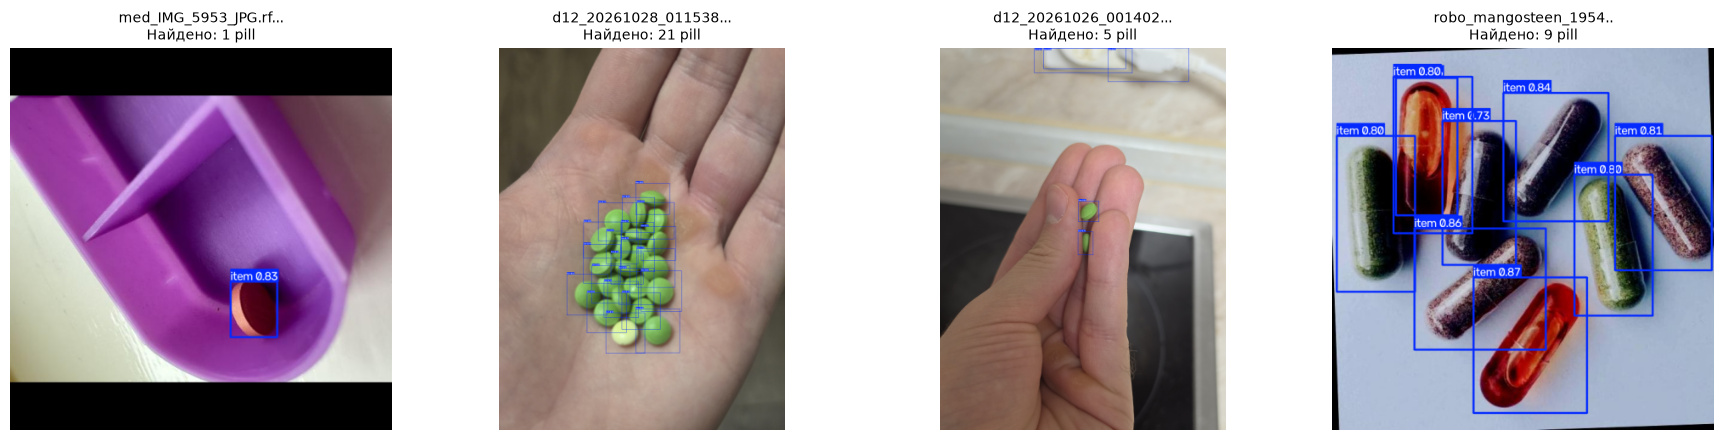

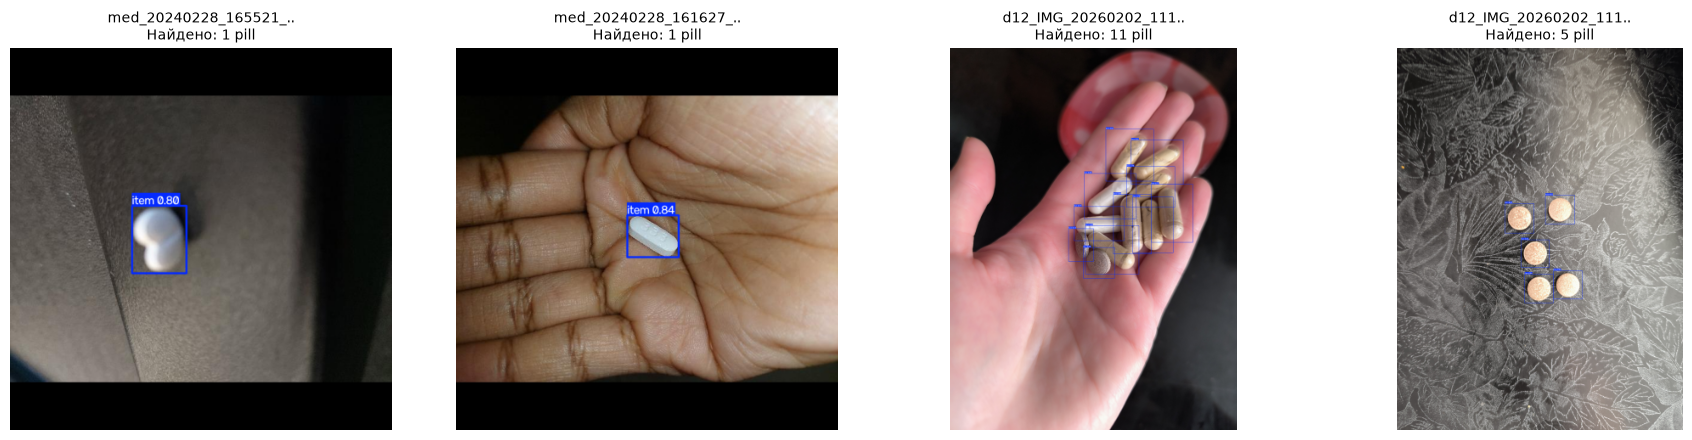

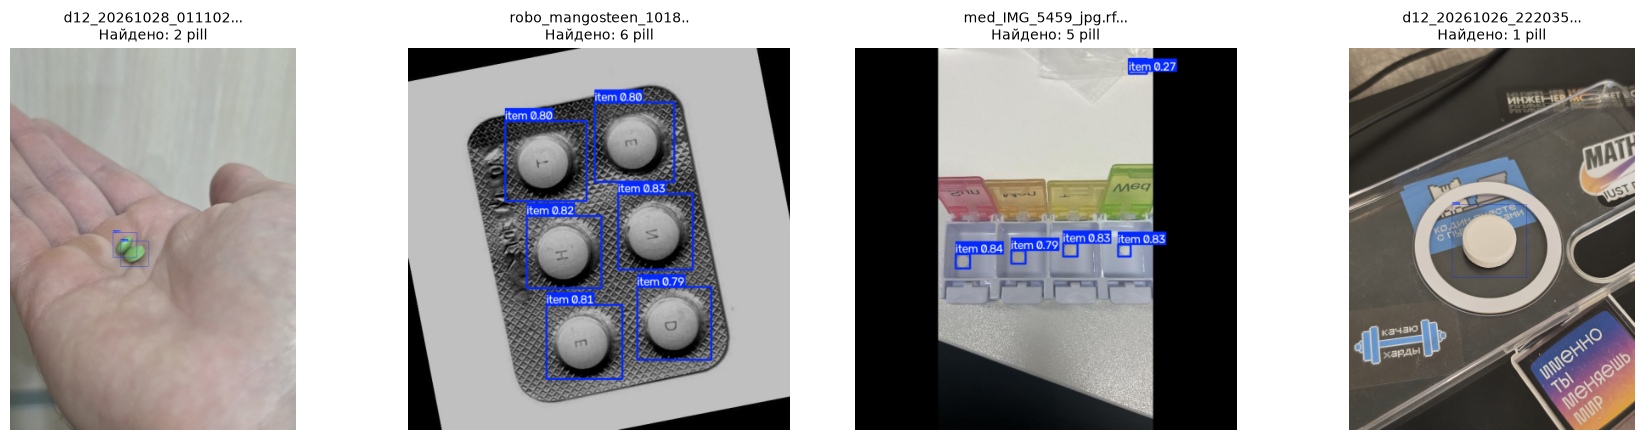

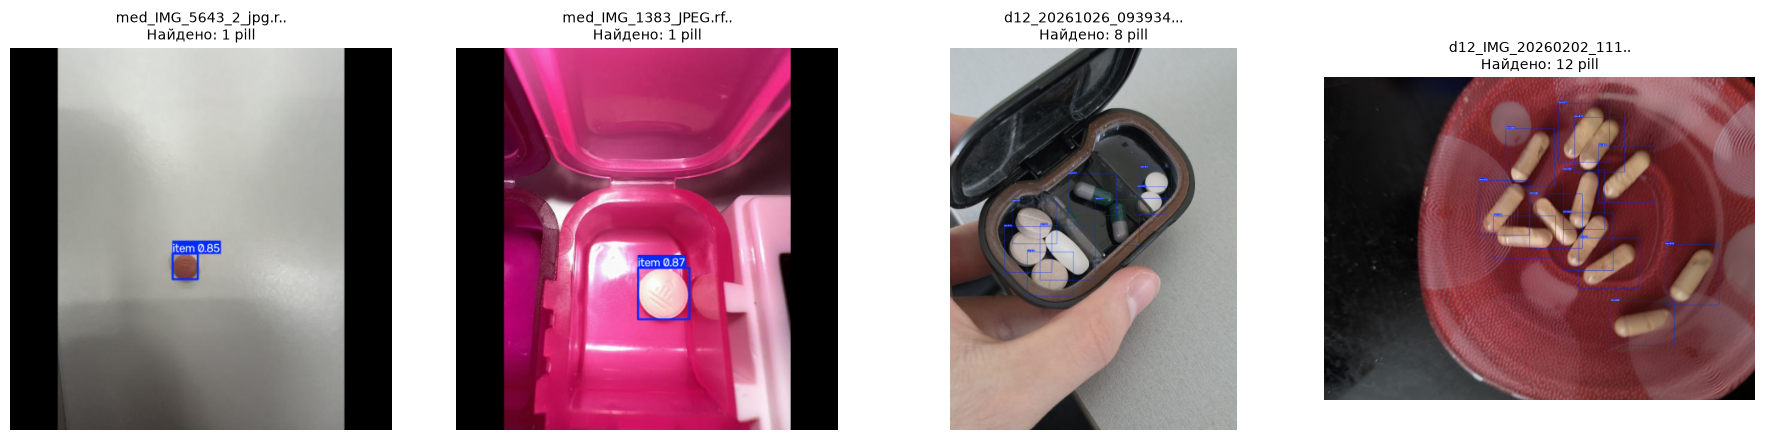

In [9]:
import random
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Загрузка весов v8
MODEL_PATH = Path(
    r"D:\Tabmed\Tabmed_ml\runs\detect\tabmed_yolo26n_v8_single_det\weights\best.pt"
)
if not MODEL_PATH.is_file():
    MODEL_PATH = Path(r"D:\Tabmed\Tabmed_ml\best.pt")

model = YOLO(str(MODEL_PATH))

# 2. Выборка 16 снимков из val
VAL_IMG_DIR = Path(r"D:\Tabmed\Datasets\dataset_v8\images\val")
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
all_imgs = [
    p for p in VAL_IMG_DIR.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXTS
]

random.seed(42)
sampled = random.sample(all_imgs, min(16, len(all_imgs)))

print(f"Отрисовка 16 тестовых кадров (по 4 в ряд)...")

# 3. Построчный вывод: 4 ряда по 4 изображения
for row_idx in range(4):
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

    for col_idx in range(4):
        item_idx = row_idx * 4 + col_idx
        ax = axes[col_idx]

        if item_idx < len(sampled):
            img_p = sampled[item_idx]

            # Предсказание детектора
            res = model.predict(source=str(img_p), conf=0.25, verbose=False)[0]

            # Отрисовка рамок
            annotated = res.plot(line_width=2, font_size=1)
            annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

            # Легкое сжатие для быстрого рендера в окне блокнота
            h, w = annotated_rgb.shape[:2]
            scale = 450 / max(h, w)
            preview = cv2.resize(
                annotated_rgb,
                (int(w * scale), int(h * scale)),
                interpolation=cv2.INTER_AREA,
            )

            ax.imshow(preview)
            ax.set_title(
                f"{img_p.name[:20]}..\nНайдено: {len(res.boxes)} pill",
                fontsize=10,
            )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# Создания датасета для сегментации, замена рамок на полигоны

In [10]:
import shutil
from pathlib import Path
import cv2
import numpy as np
import torch
from ultralytics import SAM

SRC_DIR = Path(r"D:\Tabmed\Datasets\dataset_v8")
DST_DIR = Path(r"D:\Tabmed\Datasets\dataset_v8_seg")
SAM_WEIGHTS = Path(r"D:\Tabmed\Tabmed_ml\weights\other\sam2_b.pt")
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print(f"CUDA доступна: {torch.cuda.is_available()}")
device = 0 if torch.cuda.is_available() else "cpu"

# 1. Загрузка и принудительный перенос SAM 2 на GPU
sam_model = SAM(str(SAM_WEIGHTS))
sam_model.to(f"cuda:{device}")
print(f"SAM 2 запущен на: {torch.cuda.get_device_name(device)}")

for split in ["train", "val"]:
    src_img_dir = SRC_DIR / "images" / split
    src_lbl_dir = SRC_DIR / "labels" / split
    dst_img_dir = DST_DIR / "images" / split
    dst_lbl_dir = DST_DIR / "labels" / split
    dst_img_dir.mkdir(parents=True, exist_ok=True)
    dst_lbl_dir.mkdir(parents=True, exist_ok=True)

    img_files = [
        p
        for p in src_img_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMG_EXTS
    ]
    total = len(img_files)
    converted_count = 0

    print(f"\n[GPU Ускорение] Обработка сплита '{split}' ({total} фото)...")

    for idx, img_path in enumerate(img_files, 1):
        lbl_path = src_lbl_dir / f"{img_path.stem}.txt"
        if not lbl_path.is_file():
            continue

        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]

        lines = [
            line.strip().split()
            for line in lbl_path.read_text(encoding="utf-8").splitlines()
            if line.strip()
        ]

        boxes_list = []
        for parts in lines:
            coords = list(map(float, parts[1:]))
            if len(coords) == 4:
                xc, yc, bw, bh = coords
                x1 = max(0, int((xc - bw / 2.0) * w))
                y1 = max(0, int((yc - bh / 2.0) * h))
                x2 = min(w - 1, int((xc + bw / 2.0) * w))
                y2 = min(h - 1, int((yc + bh / 2.0) * h))
                if (x2 - x1) >= 4 and (y2 - y1) >= 4:
                    boxes_list.append([x1, y1, x2, y2])

        if not boxes_list:
            continue

        seg_lines = []
        try:
            # ПАКЕТНЫЙ ЗАПУСК НА GPU: передаем сразу ВСЕ рамки кадра за один проход
            results = sam_model(
                img_path, bboxes=boxes_list, device=device, verbose=False
            )

            if results and results[0].masks is not None:
                masks = results[0].masks.data.cpu().numpy().astype(np.uint8)

                for i in range(len(masks)):
                    mask = cv2.resize(
                        masks[i], (w, h), interpolation=cv2.INTER_NEAREST
                    )
                    contours, _ = cv2.findContours(
                        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
                    )
                    if not contours:
                        continue

                    hull = cv2.convexHull(max(contours, key=cv2.contourArea))
                    perim = cv2.arcLength(hull, True)
                    if perim == 0:
                        continue
                    approx = cv2.approxPolyDP(hull, 0.003 * perim, True)
                    if len(approx) < 3:
                        continue

                    pts_norm = []
                    for pt in approx.reshape(-1, 2):
                        pts_norm.extend(
                            [f"{pt[0]/w:.6f}", f"{pt[1]/h:.6f}"]
                        )
                    seg_lines.append("0 " + " ".join(pts_norm))
        except Exception:
            continue

        if seg_lines:
            shutil.copy2(img_path, dst_img_dir / img_path.name)
            (dst_lbl_dir / f"{img_path.stem}.txt").write_text(
                "\n".join(seg_lines) + "\n", encoding="utf-8"
            )
            converted_count += 1

        if idx % 50 == 0 or idx == total:
            print(f"  [{split}] Обработано {idx}/{total} (сохранено: {converted_count})")

# data.yaml
yaml_content = f"""path: {DST_DIR.as_posix()}
train: images/train
val: images/val

names:
  0: pill
"""
(DST_DIR / "data.yaml").write_text(yaml_content, encoding="utf-8")
print(f"\n[ГОТОВО] Сконвертировано на GPU в: {DST_DIR}")

CUDA доступна: True
SAM 2 запущен на: NVIDIA GeForce RTX 4060 Ti

[GPU Ускорение] Обработка сплита 'train' (436 фото)...
  [train] Обработано 50/436 (сохранено: 50)
  [train] Обработано 100/436 (сохранено: 100)
  [train] Обработано 400/436 (сохранено: 152)
  [train] Обработано 436/436 (сохранено: 188)

[GPU Ускорение] Обработка сплита 'val' (109 фото)...
  [val] Обработано 100/109 (сохранено: 45)
  [val] Обработано 109/109 (сохранено: 54)

[ГОТОВО] Сконвертировано на GPU в: D:\Tabmed\Datasets\dataset_v8_seg


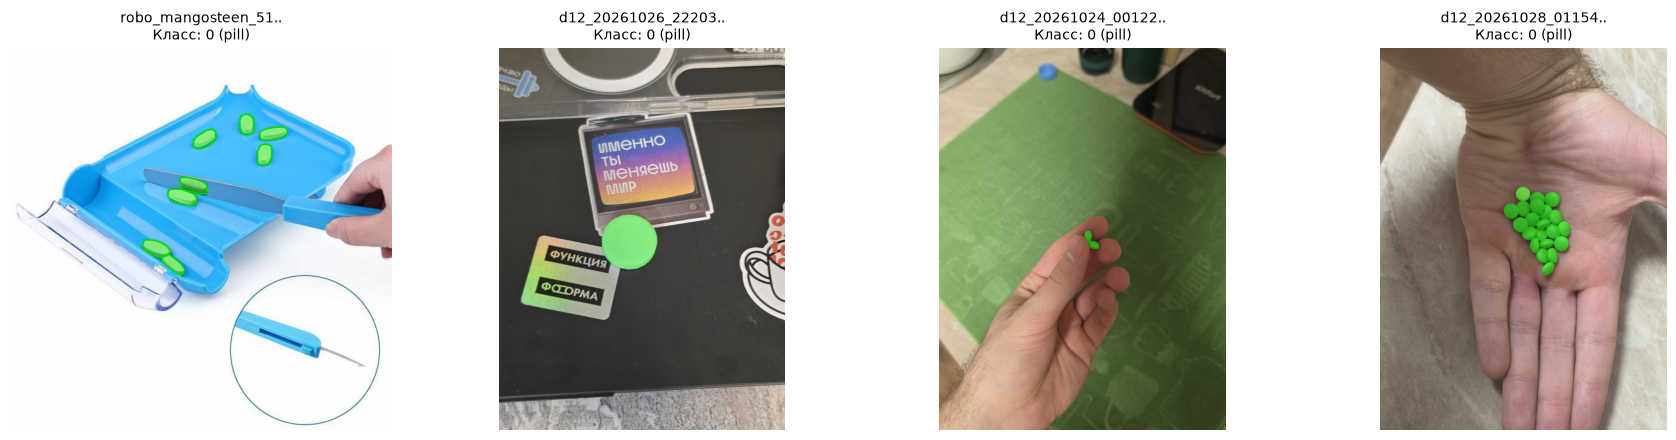

In [11]:
from pathlib import Path
import random
import cv2
import matplotlib.pyplot as plt
import numpy as np

SEG_DIR = Path(r"D:\Tabmed\Datasets\dataset_v8_seg")
train_imgs = list((SEG_DIR / "images" / "train").glob("*.jpg")) + list(
    (SEG_DIR / "images" / "train").glob("*.png")
)

random.seed(42)
sampled = random.sample(train_imgs, min(4, len(train_imgs)))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for idx, img_p in enumerate(sampled):
    lbl_p = SEG_DIR / "labels" / "train" / f"{img_p.stem}.txt"
    img = cv2.imread(str(img_p))
    h, w = img.shape[:2]

    overlay = img.copy()

    if lbl_p.is_file():
        lines = [
            l.strip().split()
            for l in lbl_p.read_text(encoding="utf-8").splitlines()
            if l.strip()
        ]
        for line in lines:
            pts = list(map(float, line[1:]))
            poly = np.array(
                [
                    [int(pts[i] * w), int(pts[i + 1] * h)]
                    for i in range(0, len(pts), 2)
                ],
                dtype=np.int32,
            )
            # Заливка полигона маски зеленым цветом
            cv2.fillPoly(overlay, [poly], (0, 255, 0))
            cv2.polylines(img, [poly], True, (0, 200, 0), 2)

    res = cv2.addWeighted(overlay, 0.4, img, 0.6, 0)
    res_rgb = cv2.cvtColor(res, cv2.COLOR_BGR2RGB)

    axes[idx].imshow(res_rgb)
    axes[idx].set_title(f"{img_p.name[:18]}..\nКласс: 0 (pill)", fontsize=10)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

In [12]:
import shutil
from pathlib import Path
import cv2
import numpy as np

DATASET_DIR = Path(r"D:\Tabmed\Datasets\dataset_v8_seg")
OUT_DIR = Path(r"D:\Tabmed\inspect_v8_masks")
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Очищаем или создаем целевую директорию
if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Цвет маски для единого класса 0 (pill) — зеленый BGR
COLOR_MASK = (0, 255, 0)
COLOR_BORDER = (0, 200, 0)

total_exported = 0

for split in ["train", "val"]:
    img_dir = DATASET_DIR / "images" / split
    lbl_dir = DATASET_DIR / "labels" / split
    out_split_dir = OUT_DIR / split
    out_split_dir.mkdir(parents=True, exist_ok=True)

    if not img_dir.exists():
        continue

    img_files = [
        p for p in img_dir.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXTS
    ]
    print(f"\nГенерация масок для сплита '{split}' ({len(img_files)} фото)...")

    for img_p in img_files:
        lbl_p = lbl_dir / f"{img_p.stem}.txt"
        img = cv2.imread(str(img_p))
        if img is None:
            continue

        h, w = img.shape[:2]
        overlay = img.copy()

        if lbl_p.is_file():
            lines = [
                line.strip().split()
                for line in lbl_p.read_text(encoding="utf-8").splitlines()
                if line.strip()
            ]

            pill_count = 0
            for parts in lines:
                if len(parts) < 7:
                    continue

                coords = list(map(float, parts[1:]))
                poly = np.array(
                    [
                        [int(coords[i] * w), int(coords[i + 1] * h)]
                        for i in range(0, len(coords), 2)
                    ],
                    dtype=np.int32,
                )

                # Заливка полигона и рисование контурной линии
                cv2.fillPoly(overlay, [poly], COLOR_MASK)
                cv2.polylines(
                    img,
                    [poly],
                    isClosed=True,
                    color=COLOR_BORDER,
                    thickness=2,
                    lineType=cv2.LINE_AA,
                )
                pill_count += 1

            # Смешиваем оригинал и полупрозрачную маску (40% прозрачности)
            blended = cv2.addWeighted(overlay, 0.4, img, 0.6, 0)

            # Добавляем плашку с количеством распознанных таблеток
            cv2.putText(
                blended,
                f"Pills: {pill_count}",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                1.0,
                (0, 255, 0),
                2,
                cv2.LINE_AA,
            )

            out_file = out_split_dir / f"viz_{img_p.name}"
            cv2.imwrite(str(out_file), blended)
            total_exported += 1

print("\n" + "=" * 55)
print(f"[ГОТОВО] Все визуализированные маски сохранены:")
print(f"Путь: {OUT_DIR.resolve()}")
print(f"Всего файлов выгружено: {total_exported}")
print("=" * 55)


Генерация масок для сплита 'train' (188 фото)...

Генерация масок для сплита 'val' (54 фото)...

[ГОТОВО] Все визуализированные маски сохранены:
Путь: D:\Tabmed\inspect_v8_masks
Всего файлов выгружено: 242


In [13]:
from pathlib import Path

INSPECT_DIR = Path(r"D:\Tabmed\inspect_v8_masks")
SEG_DIR = Path(r"D:\Tabmed\Datasets\dataset_v8_seg")
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "val"]:
    inspect_split = INSPECT_DIR / split
    img_split = SEG_DIR / "images" / split
    lbl_split = SEG_DIR / "labels" / split

    # Собираем имена файлов, которые ВЫЖИЛИ после твоей ручной чистки (убираем префикс 'viz_')
    kept_stems = {
        p.stem.replace("viz_", "", 1)
        for p in inspect_split.iterdir()
        if p.is_file() and p.suffix.lower() in IMG_EXTS
    }

    removed_imgs = 0
    for img_p in list(img_split.iterdir()):
        if img_p.is_file() and img_p.stem not in kept_stems:
            img_p.unlink()
            removed_imgs += 1
            lbl_p = lbl_split / f"{img_p.stem}.txt"
            if lbl_p.is_file():
                lbl_p.unlink()

    final_imgs = len(list(img_split.glob("*.*")))
    final_lbls = len(list(lbl_split.glob("*.txt")))
    print(
        f"Сплит '{split}': удалено отбракованных = {removed_imgs} | Осталось чистых пар: {final_imgs} (меток: {final_lbls})"
    )

Сплит 'train': удалено отбракованных = 42 | Осталось чистых пар: 146 (меток: 146)
Сплит 'val': удалено отбракованных = 16 | Осталось чистых пар: 38 (меток: 38)


In [14]:
import json
import shutil
from pathlib import Path
import cv2
import numpy as np

# 1. Поиск оригинального MEDISEG
MEDISEG_DIRS = [
    Path(r"D:\Tabmed\Mediseg_dataset\32pills"),
    Path(r"D:\Tabmed\Mediseg_dataset\3pills"),
    Path(r"D:\Tabmed\Datasets\MEDISEG\32pills"),
    Path(r"D:\Tabmed\Datasets\MEDISEG\3pills"),
    Path(r"D:\Tabmed\Datasets\dataset_clear_mediseg"),
]

# Ищем annotations.json
ann_path = None
for d in MEDISEG_DIRS:
    candidate = d / "annotations.json"
    if candidate.is_file():
        ann_path = candidate
        break

if not ann_path:
    # Глобальный поиск на всякий случай
    all_anns = list(Path(r"D:\Tabmed").glob("**/annotations.json"))
    if all_anns:
        ann_path = all_anns[0]

assert (
    ann_path and ann_path.is_file()
), "Не удалось найти annotations.json от MEDISEG!"
print(f"Найден файл разметки MEDISEG: {ann_path}")

# Читаем COCO аннотации
with open(ann_path, "r", encoding="utf-8") as f:
    coco_data = json.load(f)

# Индекс: имя файла без расширения -> (width, height, list of polygons)
mediseg_masks = {}
img_id_to_meta = {
    img["id"]: (img["file_name"], img["width"], img["height"])
    for img in coco_data["images"]
}

for ann in coco_data["annotations"]:
    if "segmentation" in ann and ann["segmentation"]:
        img_id = ann["image_id"]
        fname, w, h = img_id_to_meta[img_id]
        stem = Path(fname).stem
        if stem not in mediseg_masks:
            mediseg_masks[stem] = {"w": w, "h": h, "polys": []}
        for poly in ann["segmentation"]:
            if len(poly) >= 6:
                mediseg_masks[stem]["polys"].append(poly)

print(
    f"В базе MEDISEG проиндексировано снимков с масками: {len(mediseg_masks)}"
)

# 2. Перенос в наш сегментационный датасет
V8_DIR = Path(r"D:\Tabmed\Datasets\dataset_v8")
SEG_DIR = Path(r"D:\Tabmed\Datasets\dataset_v8_seg")
added_count = 0

for split in ["train", "val"]:
    v8_img_split = V8_DIR / "images" / split
    dst_img_split = SEG_DIR / "images" / split
    dst_lbl_split = SEG_DIR / "labels" / split

    dst_img_split.mkdir(parents=True, exist_ok=True)
    dst_lbl_split.mkdir(parents=True, exist_ok=True)

    # Ищем кадры с префиксом med_
    med_imgs = list(v8_img_split.glob("med_*.*"))

    for img_p in med_imgs:
        # Убираем префикс med_, чтобы найти оригинальное имя в annotations.json
        orig_stem = img_p.stem.replace("med_", "", 1)

        # Если файл был из Roboflow-версии с длинным хэшем, пробуем найти базовую часть
        matched_key = None
        if orig_stem in mediseg_masks:
            matched_key = orig_stem
        else:
            for k in mediseg_masks.keys():
                if k in orig_stem or orig_stem in k:
                    matched_key = k
                    break

        if not matched_key:
            continue

        meta = mediseg_masks[matched_key]
        w, h = float(meta["w"]), float(meta["h"])

        seg_lines = []
        for poly in meta["polys"]:
            # Превращаем в полигон пикселей
            pts = np.array(
                [
                    [int(poly[i]), int(poly[i + 1])]
                    for i in range(0, len(poly), 2)
                ],
                dtype=np.int32,
            )

            # Прогоняем через Convex Hull для идеальной гладкости
            hull = cv2.convexHull(pts)
            peri = cv2.arcLength(hull, True)
            if peri == 0:
                continue
            approx = cv2.approxPolyDP(hull, 0.003 * peri, True)
            if len(approx) < 3:
                continue

            # Нормализуем в диапазон [0.0, 1.0]
            norm_pts = []
            for pt in approx.reshape(-1, 2):
                nx = max(0.0, min(1.0, pt[0] / w))
                ny = max(0.0, min(1.0, pt[1] / h))
                norm_pts.extend([f"{nx:.6f}", f"{ny:.6f}"])

            seg_lines.append("0 " + " ".join(norm_pts))

        if seg_lines:
            shutil.copy2(img_p, dst_img_split / img_p.name)
            (dst_lbl_split / f"{img_p.stem}.txt").write_text(
                "\n".join(seg_lines) + "\n", encoding="utf-8"
            )
            added_count += 1

print("\n" + "=" * 55)
print(f"[УСПЕХ] Восстановлено нативных масок MEDISEG: {added_count} кадров!")
train_total = len(list((SEG_DIR / "images" / "train").glob("*.*")))
val_total = len(list((SEG_DIR / "images" / "val").glob("*.*")))
print(f"Итоговый состав dataset_v8_seg прямо сейчас:")
print(f"  • Train: {train_total} фото")
print(f"  • Val:   {val_total} фото")
print(f"  • Всего: {train_total + val_total} фото")
print("=" * 55)

Найден файл разметки MEDISEG: D:\Tabmed\Datasets\MEDISEG\32pills\annotations.json
В базе MEDISEG проиндексировано снимков с масками: 8259

[УСПЕХ] Восстановлено нативных масок MEDISEG: 303 кадров!
Итоговый состав dataset_v8_seg прямо сейчас:
  • Train: 394 фото
  • Val:   93 фото
  • Всего: 487 фото


# Обучение

In [16]:
from pathlib import Path
from ultralytics import YOLO

DATA_YAML = Path(r"D:\Tabmed\Datasets\dataset_v8_seg\data.yaml")
WEIGHTS_SEG = Path(r"D:\Tabmed\Tabmed_ml\weights\segmentation\yolo26n-seg.pt")
if not WEIGHTS_SEG.is_file():
    WEIGHTS_SEG = Path(r"D:\Tabmed\Tabmed_ml\yolo26n-seg.pt")

PROJECT_DIR = Path(r"D:\Tabmed\Tabmed_ml\runs\segment")

model = YOLO(str(WEIGHTS_SEG))

results = model.train(
    data=str(DATA_YAML),
    single_cls=True,  # Фокусируемся на качестве маски (mask_loss), без классификации
    epochs=80,
    patience=20,  # Ранняя остановка, если mAP перестал расти
    imgsz=640,
    batch=16,
    device=0,  # RTX 4060 Ti
    workers=2,  # Оптимально для Windows DataLoader
    project=str(PROJECT_DIR),
    name="tabmed_yolo26n_v8_single_seg",
    exist_ok=True,
    # Аугментации для гладких контуров и устойчивости к ракурсам
    degrees=180.0,
    fliplr=0.5,
    flipud=0.5,
    scale=0.4,
    mosaic=1.0,
    hsv_h=0.015,
    hsv_s=0.4,
    hsv_v=0.3,
)

best_seg = (
    PROJECT_DIR / "tabmed_yolo26n_v8_single_seg" / "weights" / "best.pt"
)
print(f"\n[ГОТОВО] Обучение завершено! Лучшие веса сохранены:")
print(best_seg)

New https://pypi.org/project/ultralytics/8.4.202 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.189  Python-3.12.0 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 16380MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Tabmed\Datasets\dataset_v8_seg\data.yaml, degrees=180.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=tra

Ultralytics 8.4.189  Python-3.12.0 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 16380MiB)
YOLO26n-seg summary (fused): 137 layers, 2,703,783 parameters, 0 gradients, 9.1 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 834.3±753.8 MB/s, size: 538.7 KB)
val: Scanning D:\Tabmed\Datasets\dataset_v8_seg\labels\val.cache... 93 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 93/93  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.3s/it 13.5s0.5s3
                   all         93        359      0.979      0.927      0.979      0.843      0.976      0.925      0.977      0.791
Speed: 4.0ms preprocess, 4.8ms inference, 0.0ms loss, 4.3ms postprocess per image
Results saved to D:\Tabmed\Tabmed_ml\runs\segment\val

Рамки: mAP50(B) = 0.979 | mAP50-95(B) = 0.843
Маски: mAP50(M) = 0.977 | mAP50-95(M) = 0.791
✓ Веса продублированы в best_v8_single_seg.pt


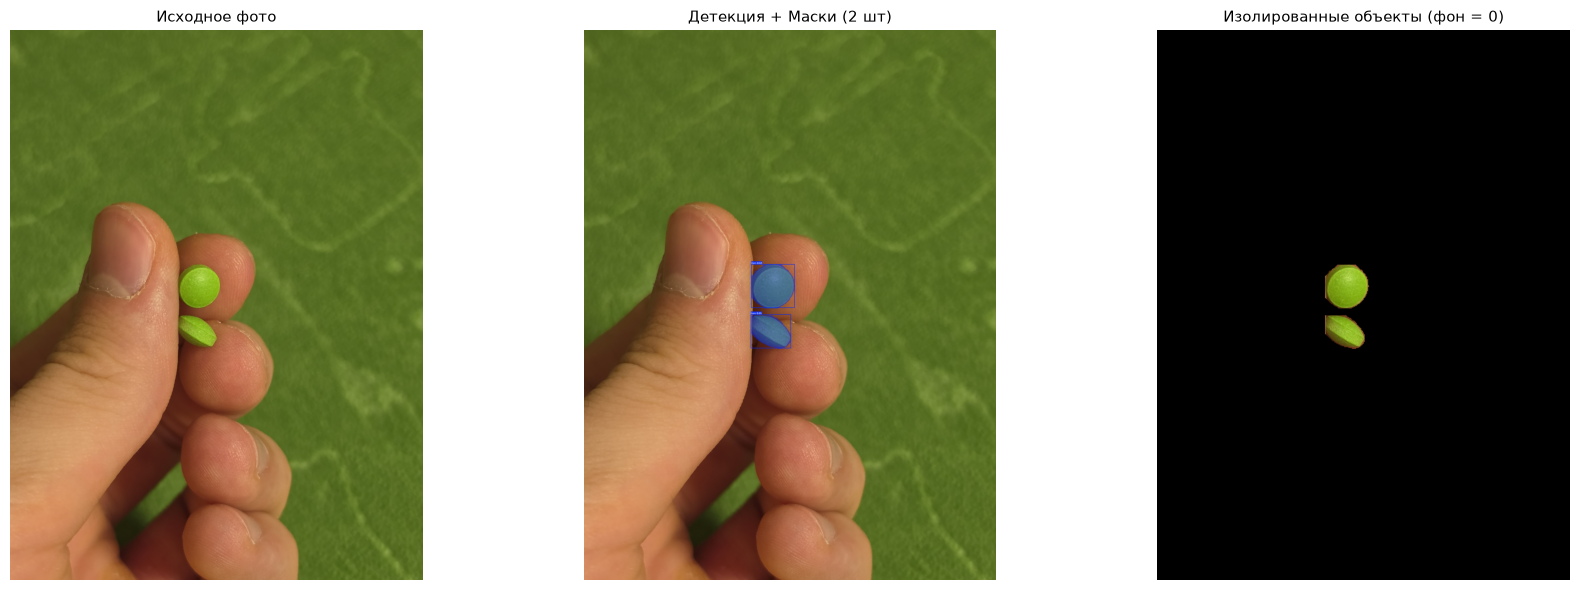

In [17]:
import shutil
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

BEST_SEG = Path(
    r"D:\Tabmed\Tabmed_ml\runs\segment\tabmed_yolo26n_v8_single_seg\weights\best.pt"
)
BACKUP_SEG = Path(
    r"D:\Tabmed\Tabmed_ml\weights\segmentation\best_v8_single_seg.pt"
)
DATA_YAML = Path(r"D:\Tabmed\Datasets\dataset_v8_seg\data.yaml")
TEST_IMG = Path(r"D:\Tabmed\Tabmed_ml\test.jpg")

# 1. Валидация
model = YOLO(str(BEST_SEG))
metrics = model.val(
    data=str(DATA_YAML), single_cls=True, imgsz=640, batch=16, device=0
)

print("\n" + "=" * 50)
print(
    f"Рамки: mAP50(B) = {metrics.results_dict.get('metrics/mAP50(B)', 0):.3f} | mAP50-95(B) = {metrics.results_dict.get('metrics/mAP50-95(B)', 0):.3f}"
)
print(
    f"Маски: mAP50(M) = {metrics.results_dict.get('metrics/mAP50(M)', 0):.3f} | mAP50-95(M) = {metrics.results_dict.get('metrics/mAP50-95(M)', 0):.3f}"
)
print("=" * 50)

# Сохраняем в каталог сегментационных весов
shutil.copy2(BEST_SEG, BACKUP_SEG)
print(f"✓ Веса продублированы в {BACKUP_SEG.name}")

# 2. Инференс с обнулением фона на test.jpg
if TEST_IMG.is_file():
    img_bgr = cv2.imread(str(TEST_IMG))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]

    res = model.predict(source=str(TEST_IMG), conf=0.35, verbose=False)[0]

    black_bg = np.zeros_like(img_rgb)
    if res.masks is not None:
        masks_arr = res.masks.data.cpu().numpy()
        combined_mask = np.any(masks_arr, axis=0).astype(np.uint8)
        mask_full = cv2.resize(
            combined_mask, (w, h), interpolation=cv2.INTER_NEAREST
        )
        black_bg = cv2.bitwise_and(img_rgb, img_rgb, mask=mask_full)

    annotated = cv2.cvtColor(res.plot(line_width=2), cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(img_rgb)
    axes[0].set_title("Исходное фото", fontsize=11)
    axes[0].axis("off")

    axes[1].imshow(annotated)
    axes[1].set_title(
        f"Детекция + Маски ({len(res.boxes)} шт)", fontsize=11
    )
    axes[1].axis("off")

    axes[2].imshow(black_bg)
    axes[2].set_title("Изолированные объекты (фон = 0)", fontsize=11)
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

Запуск сегментатора: D:\Tabmed\Tabmed_ml\runs\segment\tabmed_yolo26n_v8_single_seg\weights\best.pt
Отобрано валидационных снимков: 12
№   | Имя файла                        | Найдено масок   | Статус
----------------------------------------------------------------------
1   | med_IMG_5794_2_JPG.rf.f5f71093   | 1               | OK


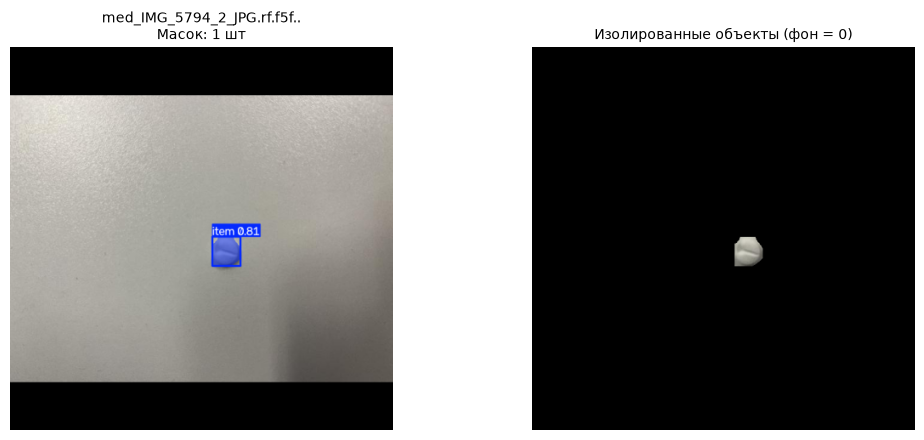

2   | d12_IMG_20260202_111534.jpg      | 12              | OK


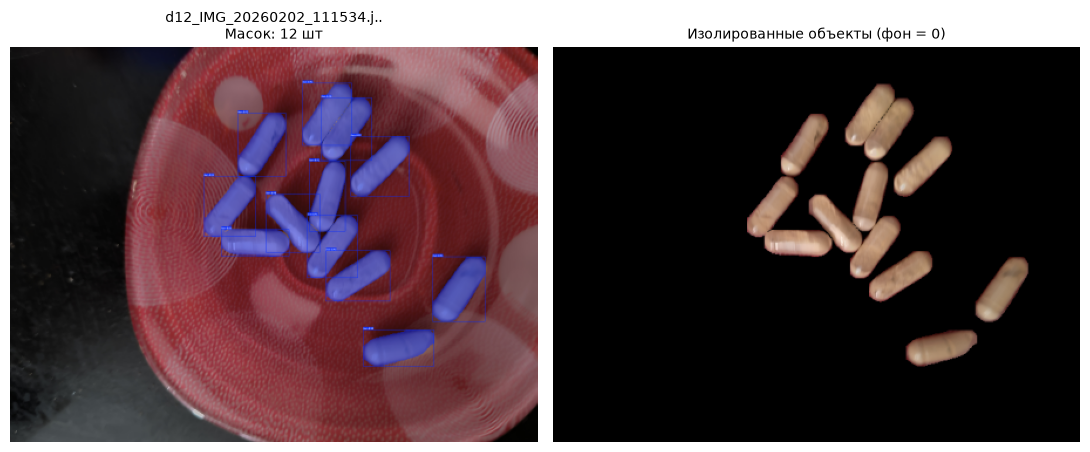

3   | med_IMG_5516_jpg.rf.068fd73e3f   | 3               | OK


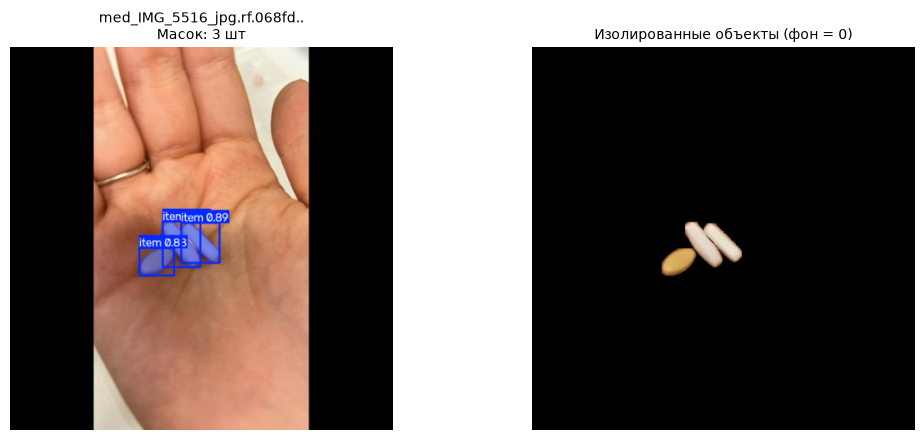

4   | med_20240313_152441_jpg.rf.19e   | 4               | OK


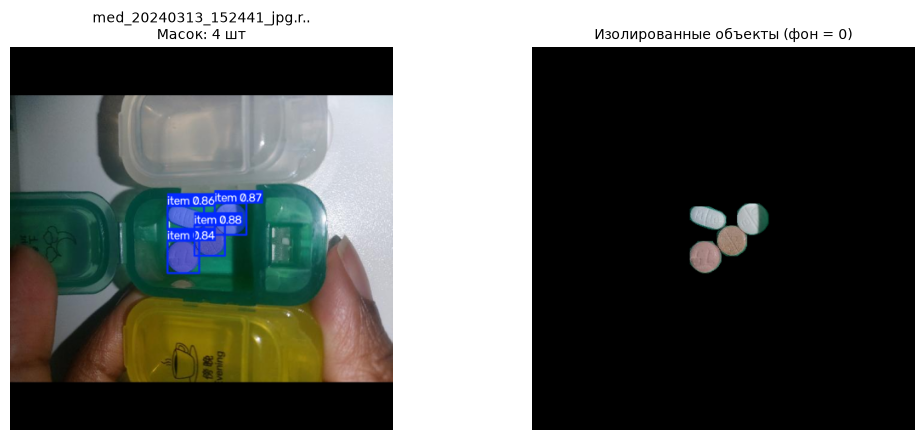

5   | med_IMG_4502_jpg.rf.37d9d93895   | 1               | OK


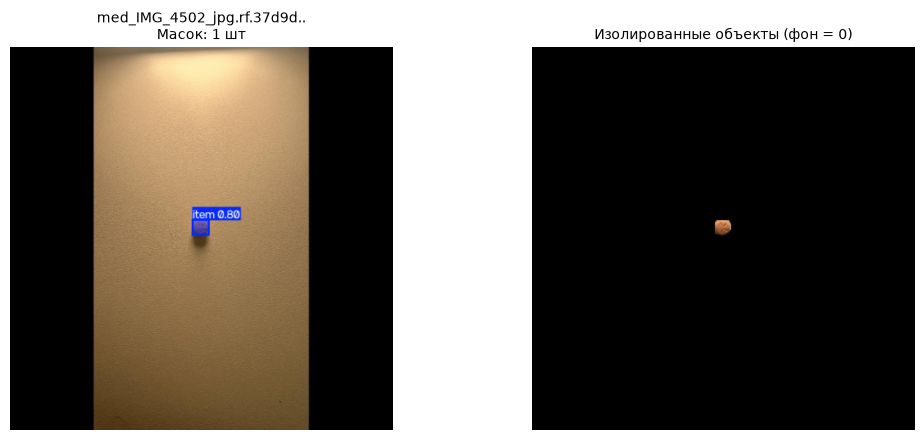

6   | d12_20261026_180651.jpg          | 1               | OK


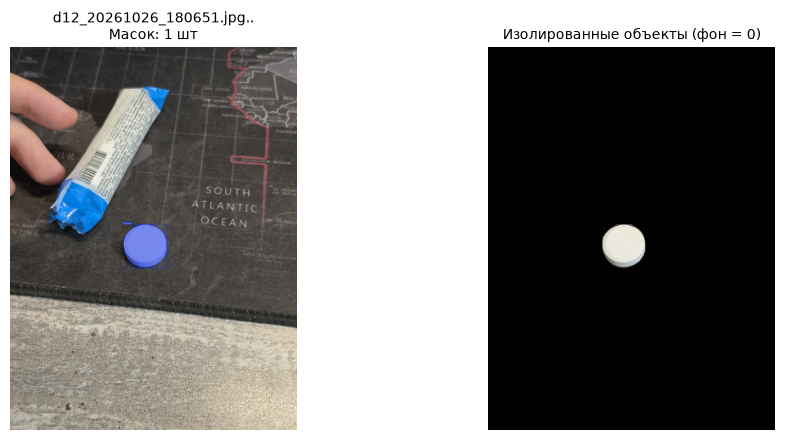

7   | robo_mangosteen_1466200796_jpg   | 4               | OK


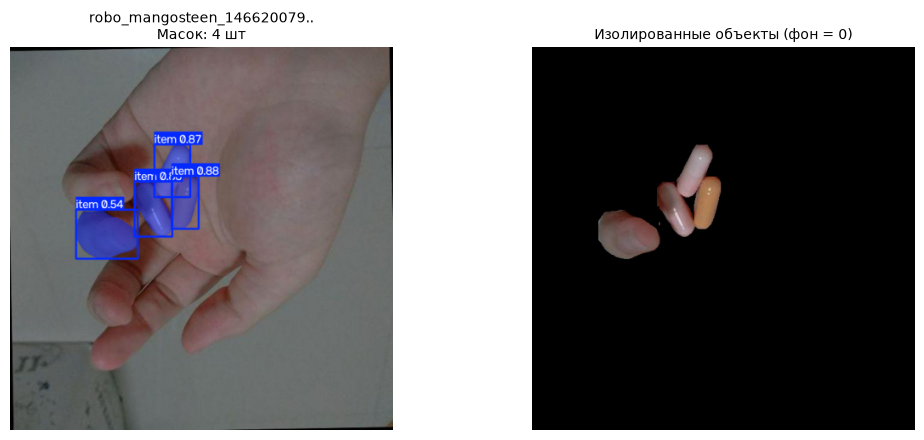

8   | med_IMG_4588_jpg.rf.318c74530c   | 1               | OK


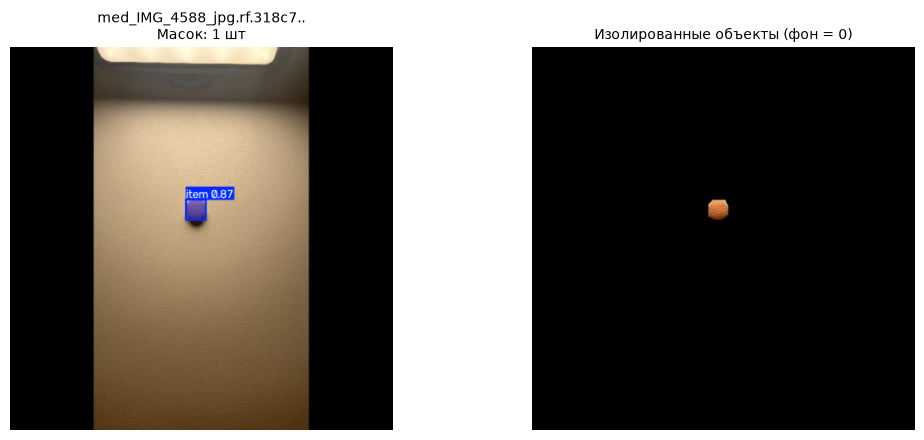

9   | med_1749_jpg.rf.098ad5c8481a0d   | 4               | OK


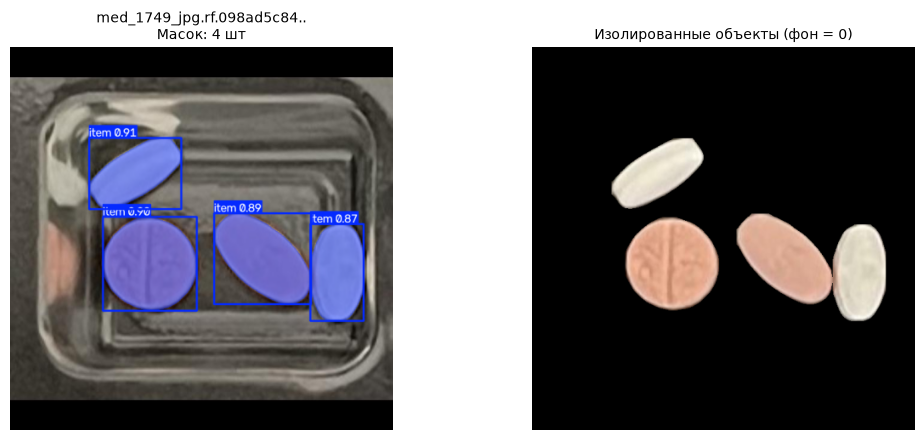

10  | med_IMG_5854_JPG.rf.aec10124fc   | 1               | OK


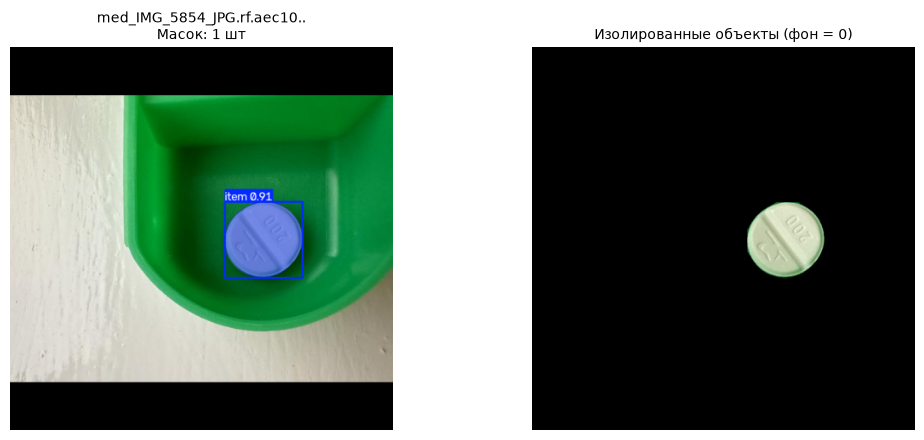

11  | med_20240228_161627_jpg.rf.668   | 1               | OK


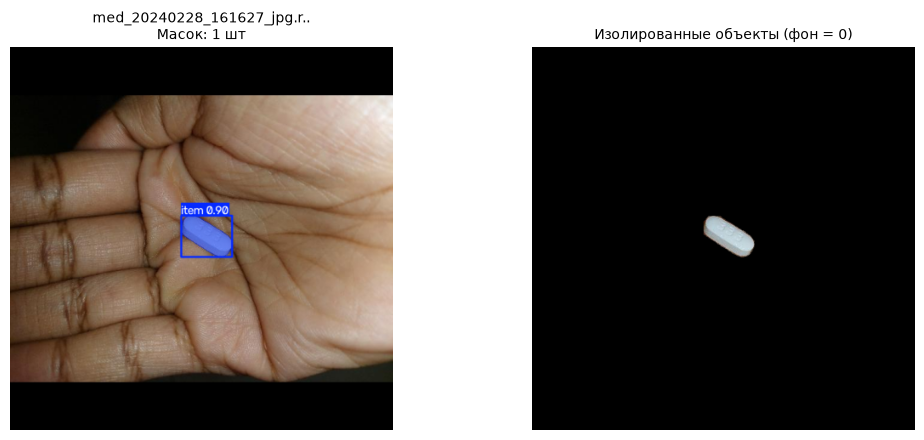

12  | med_20240306_143110_jpg.rf.ba7   | 3               | OK


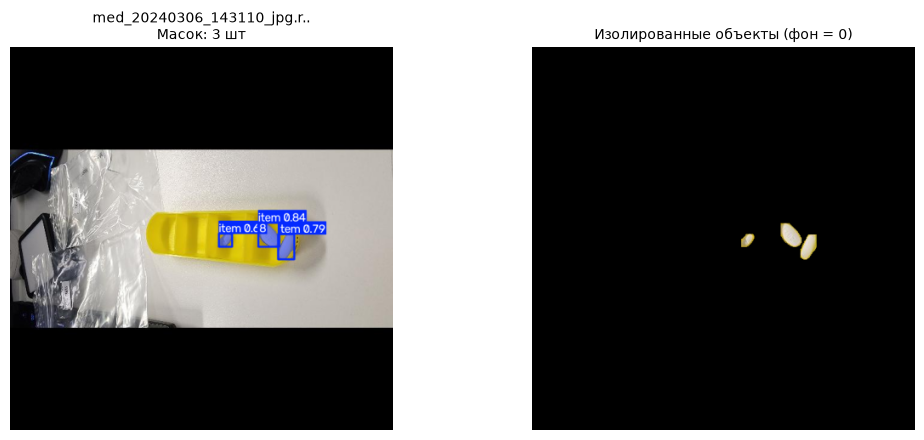

In [18]:
import random
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

# 1. Загрузка весов обученного сегментатора v8
SEG_WEIGHTS = Path(
    r"D:\Tabmed\Tabmed_ml\runs\segment\tabmed_yolo26n_v8_single_seg\weights\best.pt"
)
if not SEG_WEIGHTS.is_file():
    SEG_WEIGHTS = Path(
        r"D:\Tabmed\Tabmed_ml\weights\segmentation\best_v8_single_seg.pt"
    )

print(f"Запуск сегментатора: {SEG_WEIGHTS}")
model = YOLO(str(SEG_WEIGHTS))

# 2. Выборка 12 тестовых фото из валидации
VAL_DIR = Path(r"D:\Tabmed\Datasets\dataset_v8_seg\images\val")
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
all_val_imgs = [
    p for p in VAL_DIR.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXTS
]

random.seed(101)
sample_imgs = random.sample(all_val_imgs, min(12, len(all_val_imgs)))

print(f"Отобрано валидационных снимков: {len(sample_imgs)}")
print("=" * 70)
print(f"{'№':<3} | {'Имя файла':<32} | {'Найдено масок':<15} | {'Статус'}")
print("-" * 70)

# 3. Построчный вывод: 6 пар (каждая строка — 2 изображения)
# [Детекция с контуром] | [Изолированные таблетки (фон = 0)]
for idx, img_p in enumerate(sample_imgs, 1):
    img_bgr = cv2.imread(str(img_p))
    if img_bgr is None:
        continue
    h, w = img_bgr.shape[:2]
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Инференс с комфортным порогом 0.35
    res = model.predict(source=img_bgr, conf=0.35, imgsz=640, verbose=False)[0]

    n_masks = 0 if res.masks is None else len(res.masks)
    status = "OK" if n_masks > 0 else "Нет детекций"
    print(f"{idx:<3} | {img_p.name[:30]:<32} | {n_masks:<15} | {status}")

    # Сборка чистого черного фона
    black_bg = np.zeros_like(img_rgb)
    if res.masks is not None and len(res.masks.data) > 0:
        masks_arr = res.masks.data.cpu().numpy()
        combined = np.any(masks_arr, axis=0).astype(np.uint8)
        mask_full = cv2.resize(combined, (w, h), interpolation=cv2.INTER_NEAREST)
        black_bg = cv2.bitwise_and(img_rgb, img_rgb, mask=mask_full)

    # Отрисовка контуров и рамок
    annotated = cv2.cvtColor(res.plot(line_width=2), cv2.COLOR_BGR2RGB)

    # Сжатие превью под 450px для плавной отрисовки в VS Code
    scale = 450 / max(h, w)
    prev_ann = cv2.resize(
        annotated, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA
    )
    prev_bg = cv2.resize(
        black_bg, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA
    )

    # Выводим попарно
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    axes[0].imshow(prev_ann)
    axes[0].set_title(
        f"{img_p.name[:25]}..\nМасок: {n_masks} шт", fontsize=10
    )
    axes[0].axis("off")

    axes[1].imshow(prev_bg)
    axes[1].set_title("Изолированные объекты (фон = 0)", fontsize=10)
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()